# Exploratory Data Analysis: Global CO₂ Emissions

**Dataset:** Our World in Data, *CO₂ and Greenhouse Gas Emissions* (https://github.com/owid/co2-data)

**Input:** `data/clean/co2_clean.csv`, produced by `01_cleaning.ipynb`

**Central question:** who is responsible for global CO₂ emissions, and how has that changed over time?

| # | Section | EDA technique |
|---|---|---|
| 1 | Load the clean data | structure, summary statistics, missingness (see `01_cleaning.ipynb`) |
| 2 | Distribution of emissions | univariate analysis, skewness, log scale |
| 3 | Global trend | time series, composition |
| 4 | Who emits? | ranking, comparing three measures |
| 5 | Regions over time | grouped time series |
| 6 | Wealth and emissions | bivariate analysis, correlation |
| 7 | Decoupling | change analysis |
| 8 | Emissions embedded in trade | comparison of two definitions |
| 9 | Country profile | drill-down |
| 10 | Summary of findings | |

Emissions are in million tonnes of CO₂ (Mt) in the raw data; charts use billion tonnes (Gt) where numbers are large.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ---- chart style (one palette for the whole notebook) ----
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
# ---- project paths (work whether the kernel starts in co2-eda/ or co2-eda/notebooks/) ----
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
RAW, CLEAN, FIG = ROOT / "data" / "raw", ROOT / "data" / "clean", ROOT / "figures"
for p in (CLEAN, FIG):
    p.mkdir(parents=True, exist_ok=True)

def save(name):
    """Save the current figure to figures/ (ready to paste into slides) and show it."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Load the clean data

Cleaning (column subset, GDP per capita, country/aggregate split) and the missingness check are in
`01_cleaning.ipynb`. Here we only read the result and rebuild the views used below.


In [2]:
data = pd.read_csv(CLEAN / "co2_clean.csv")
countries = data[~data.is_aggregate]
aggregates = data[data.is_aggregate]
world = aggregates[aggregates.country == "World"].set_index("year")

YEAR = 2024       # latest year with complete data (2025 values are preliminary)
GDP_YEAR = 2022   # GDP is only available up to 2022
latest = countries[countries.year == YEAR]

print(f"{countries.country.nunique()} countries, {aggregates.country.nunique()} aggregates, "
      f"years {data.year.min()} to {data.year.max()}")
countries[["population", "gdp_per_capita", "co2", "co2_per_capita", "cumulative_co2"]].describe().T.round(2)


223 countries, 36 aggregates, years 1750 to 2025


,count,mean,std,min,25%,50%,75%,max
population,41276.0,14889842.10,71234794.61,21.00,294485.75,1989930.00,7126421.25,1.463866e+09
gdp_per_capita,15315.0,8564.63,11835.10,361.19,1848.09,4050.24,9878.74,1.635314e+05
co2,24109.0,76.30,441.10,0.00,0.24,2.60,21.82,1.241749e+04
co2_per_capita,23599.0,4.10,20.10,0.00,0.17,1.02,4.35,1.062530e+03
cumulative_co2,24109.0,2928.11,18033.62,0.00,3.17,48.63,551.25,4.393433e+05


## 2. Distribution of emissions per person

Before comparing countries, look at how the main variable is distributed.

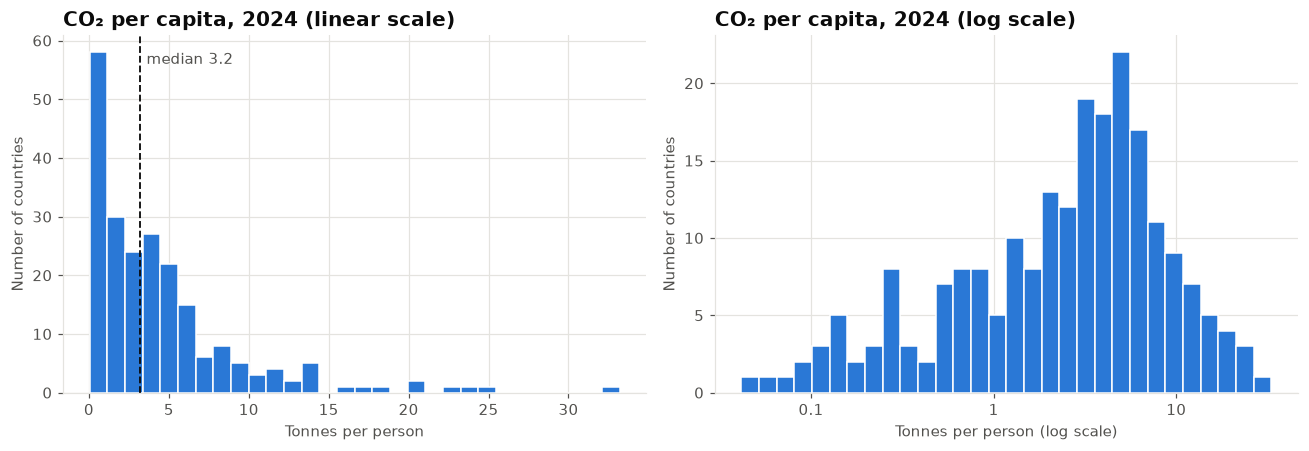

count    218.00
mean       4.47
std        5.01
min        0.04
25%        0.96
50%        3.20
75%        5.88
max       33.21

Skewness: 2.37 (linear)   -0.71 (log)
World average: 4.74 t   Countries below it: 67%
Ratio highest / lowest: 799x


In [3]:
pc = latest["co2_per_capita"].dropna()
world_pc = world.loc[YEAR, "co2_per_capita"]

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
a.hist(pc, bins=30, color=BLUE, edgecolor="white", linewidth=1)
a.axvline(pc.median(), color=INK, ls="--", lw=1.2); a.text(pc.median() + 0.4, a.get_ylim()[1] * 0.92, f"median {pc.median():.1f}", color=MUTED)
a.set(title=f"CO₂ per capita, {YEAR} (linear scale)", xlabel="Tonnes per person", ylabel="Number of countries")

b.hist(np.log10(pc), bins=30, color=BLUE, edgecolor="white", linewidth=1)
b.set_xticks([-1, 0, 1]); b.set_xticklabels(["0.1", "1", "10"])
b.set(title=f"CO₂ per capita, {YEAR} (log scale)", xlabel="Tonnes per person (log scale)", ylabel="Number of countries")
save("02_distribution")

print(pc.describe().round(2).to_string())
print(f"\nSkewness: {pc.skew():.2f} (linear)   {np.log10(pc).skew():.2f} (log)")
print(f"World average: {world_pc:.2f} t   Countries below it: {(pc < world_pc).mean():.0%}")
print(f"Ratio highest / lowest: {pc.max() / pc.min():,.0f}x")

**What we learn**

- The distribution is **strongly right-skewed** (skewness 2.4): most countries emit little per person and a few emit a lot.
- The median country emits 3.2 t per person, well below the mean of 4.5 t. About two thirds of countries are below the world average of 4.7 t.
- On a log scale the shape becomes far more balanced, so **we use log scales** whenever countries are compared on per-capita values.

## 3. Global trend: how did we get here?

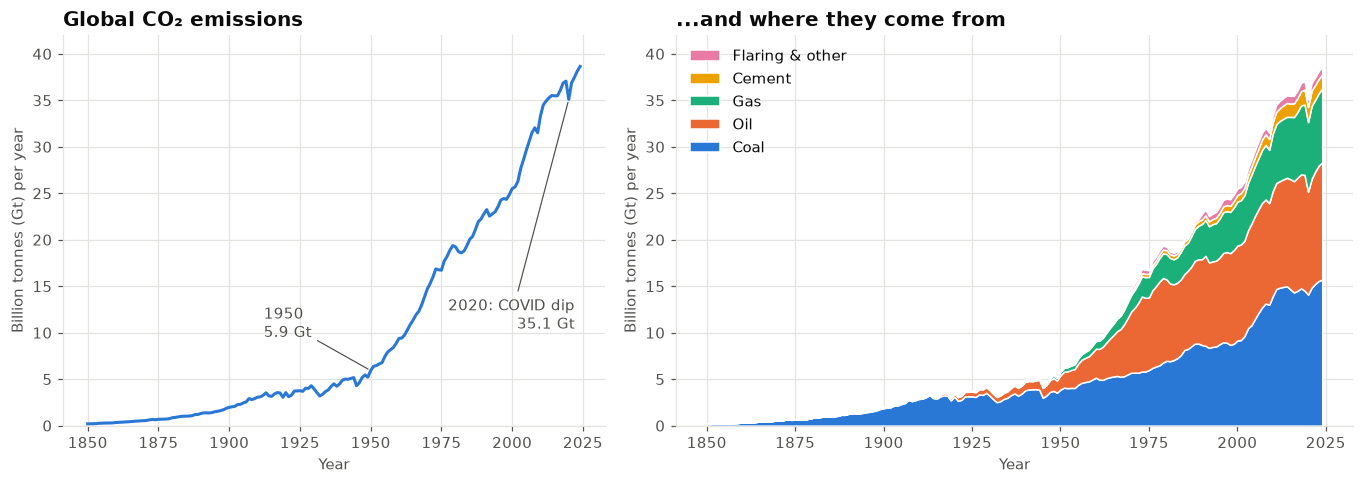

2024 total: 38.6 Gt   (6.5x the 1950 level)
2020 vs 2019: -5.3%
Share by source (%): {'Coal': 40.6, 'Oil': 32.7, 'Gas': 20.6, 'Cement': 3.9, 'Flaring & other': 2.2}
World CO₂ per capita: {1950: 2.38, 1990: 4.28, 2010: 4.75, 2024: 4.74}


In [4]:
fuels = {"Coal": "coal_co2", "Oil": "oil_co2", "Gas": "gas_co2", "Cement": "cement_co2"}
w = world.loc[1850:YEAR]
stack = pd.DataFrame({k: w[v] for k, v in fuels.items()}).fillna(0)
stack["Flaring & other"] = w[["flaring_co2", "other_industry_co2"]].fillna(0).sum(axis=1)
stack = stack / 1000   # Mt -> Gt

fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.5), gridspec_kw={"width_ratios": [1, 1.25]})
a.plot(w.index, w["co2"] / 1000, color=BLUE)
for yr, txt, off in [(1950, "1950", (-70, 22)), (2020, "2020: COVID dip", (4, -150))]:
    a.annotate(f"{txt}\n{w.loc[yr, 'co2'] / 1000:.1f} Gt", (yr, w.loc[yr, "co2"] / 1000), xytext=off,
               textcoords="offset points", color=MUTED, ha="left" if yr < 2000 else "right", arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
a.set(title="Global CO₂ emissions", xlabel="Year", ylabel="Billion tonnes (Gt) per year", ylim=(0, 42))

b.stackplot(stack.index, stack.T.values, labels=stack.columns, colors=SERIES[:5], edgecolor="white", linewidth=1)
b.set(title="...and where they come from", xlabel="Year", ylabel="Billion tonnes (Gt) per year", ylim=(0, 42))
b.legend(loc="upper left", reverse=True)
save("03_global_trend")

share = (stack.loc[YEAR] / stack.loc[YEAR].sum() * 100).round(1)
print(f"{YEAR} total: {w.loc[YEAR, 'co2'] / 1000:.1f} Gt   ({w.loc[YEAR, 'co2'] / w.loc[1950, 'co2']:.1f}x the 1950 level)")
print(f"2020 vs 2019: {w.loc[2020, 'co2'] / w.loc[2019, 'co2'] - 1:+.1%}")
print("Share by source (%):", share.to_dict())
print("World CO₂ per capita:", world.loc[[1950, 1990, 2010, YEAR], "co2_per_capita"].round(2).to_dict())

**What we learn**

- Global emissions reached **38.6 Gt in 2024, 6.5 times the 1950 level**. Almost all of the growth happened after 1950.
- **Coal is still the largest source (41%)**, followed by oil (33%) and gas (21%). Oil drove the growth from 1950 to 1975, coal drove it again after 2000.
- The 2020 pandemic caused the largest visible dip (−5.3%), and it was fully erased by 2023.
- Emissions per person have been flat at about 4.7 t since 2010, so the recent rise in the total moves in step with population growth.

## 4. Who emits? Three ways to rank countries

The answer depends entirely on the measure: total emissions today, emissions per person, or everything emitted since 1750.

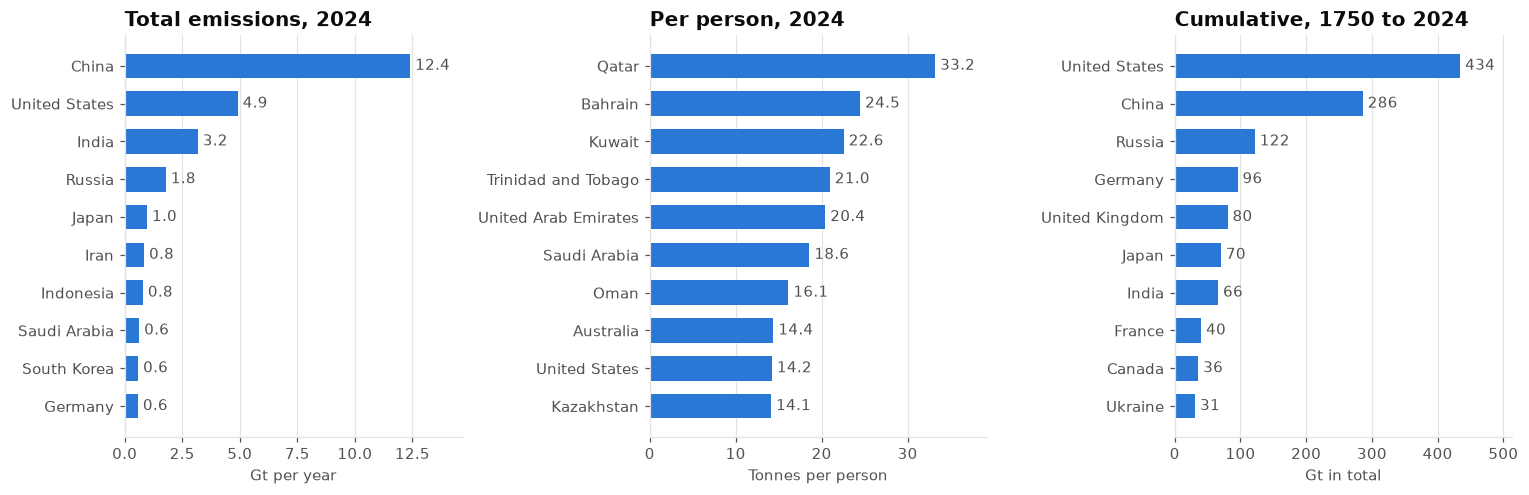

Top 10 emitters = 69% of global emissions; top 3 = 53%


,share_global_co2,share_global_cumulative_co2,co2_per_capita
country,,,
China,32.1,15.5,8.7
United States,12.7,23.5,14.2
India,8.2,3.6,2.2


In [5]:
big = latest[latest.population > 1e6]     # per-capita ranking: skip micro-states
panels = [
    (latest.nlargest(10, "co2"), "co2", 1000, f"Total emissions, {YEAR}", "Gt per year", "{:.1f}"),
    (big.nlargest(10, "co2_per_capita"), "co2_per_capita", 1, f"Per person, {YEAR}", "Tonnes per person", "{:.1f}"),
    (latest.nlargest(10, "cumulative_co2"), "cumulative_co2", 1000, f"Cumulative, 1750 to {YEAR}", "Gt in total", "{:.0f}"),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (d, col, div, title, xlabel, fmt) in zip(axes, panels):
    d = d.sort_values(col)
    ax.barh(d.country, d[col] / div, color=BLUE, height=0.65)
    for y, v in enumerate(d[col] / div):
        ax.text(v, y, " " + fmt.format(v), va="center", color=MUTED)
    ax.set(title=title, xlabel=xlabel, xlim=(0, d[col].max() / div * 1.18))
    ax.grid(axis="y", visible=False)
save("04_rankings")

top = latest.nlargest(10, "co2")
print(f"Top 10 emitters = {top.share_global_co2.sum():.0f}% of global emissions; top 3 = {top.share_global_co2.head(3).sum():.0f}%")
latest.set_index("country").loc[["China", "United States", "India"],
    ["share_global_co2", "share_global_cumulative_co2", "co2_per_capita"]].round(1)

**What we learn**

- **Total:** emissions are highly concentrated. China (32%), the United States (13%) and India (8%) produce 53% of the total, and the top 10 countries produce 69%.
- **Per person:** the ranking changes completely. Gulf oil states lead (Qatar: 33 t per person). China drops out of the top 10 (8.7 t), and India (2.2 t) is at less than half the world average.
- **Cumulative:** the United States has emitted the most over history (23.5% of the total, against 15.5% for China). Early industrialisers such as Germany and the United Kingdom appear in the top 5, although they are minor emitters today.
- **The answer to "who emits the most?" depends on the measure chosen.** This is the central insight of the project.

## 5. Regions over time

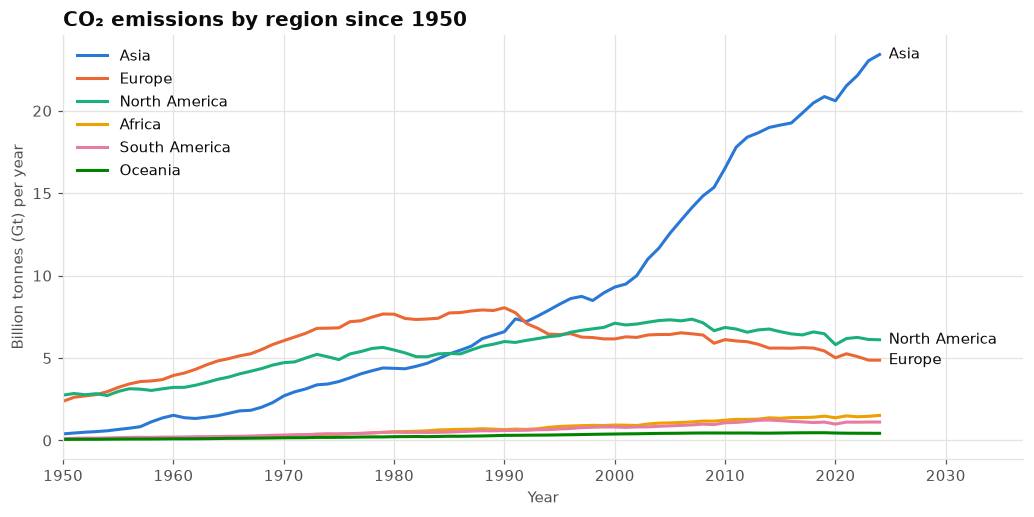

,1990,2024,peak year,change since 1990,share of world 2024
country,,,,,
Asia,6.60,23.41,2024,+255%,61%
Europe,8.05,4.87,1990,-40%,13%
North America,6.00,6.11,2007,+2%,16%
Africa,0.66,1.52,2024,+130%,4%
South America,0.60,1.12,2014,+85%,3%
Oceania,0.31,0.43,2019,+39%,1%


In [6]:
regions = ["Asia", "Europe", "North America", "Africa", "South America", "Oceania"]
reg = aggregates[aggregates.country.isin(regions) & aggregates.year.between(1950, YEAR)].pivot(index="year", columns="country", values="co2") / 1000

fig, ax = plt.subplots(figsize=(9.5, 4.8))
for r, c in zip(regions, SERIES):
    ax.plot(reg.index, reg[r], color=c, label=r)
for r in regions[:3]:
    ax.annotate(r, (YEAR, reg.loc[YEAR, r]), xytext=(6, 0), textcoords="offset points", va="center")
ax.set(title="CO₂ emissions by region since 1950", xlabel="Year", ylabel="Billion tonnes (Gt) per year", xlim=(1950, YEAR + 13))
ax.legend(loc="upper left")
save("05_regions")

summary = pd.DataFrame({"1990": reg.loc[1990], str(YEAR): reg.loc[YEAR], "peak year": reg.idxmax()})
summary["change since 1990"] = (summary[str(YEAR)] / summary["1990"] - 1).map("{:+.0%}".format)
summary[f"share of world {YEAR}"] = (reg.loc[YEAR] * 1000 / world.loc[YEAR, "co2"]).map("{:.0%}".format)
summary.loc[regions].round(2)

**What we learn**

- **Asia** went from 6.6 Gt in 1990 to 23.4 Gt in 2024 (+255%) and now produces 61% of global emissions.
- **Europe** peaked in 1990 and has fallen 40% since. **North America** has been roughly flat since 1990 (+2%), with a peak in 2007.
- **Africa** has more than doubled since 1990 but still produces only 4% of global emissions.
- The global total keeps rising because growth in Asia is larger than the decline in Europe.

## 6. Wealth and emissions

Is a richer country a higher-emitting country? We use 2022, the latest year with GDP.

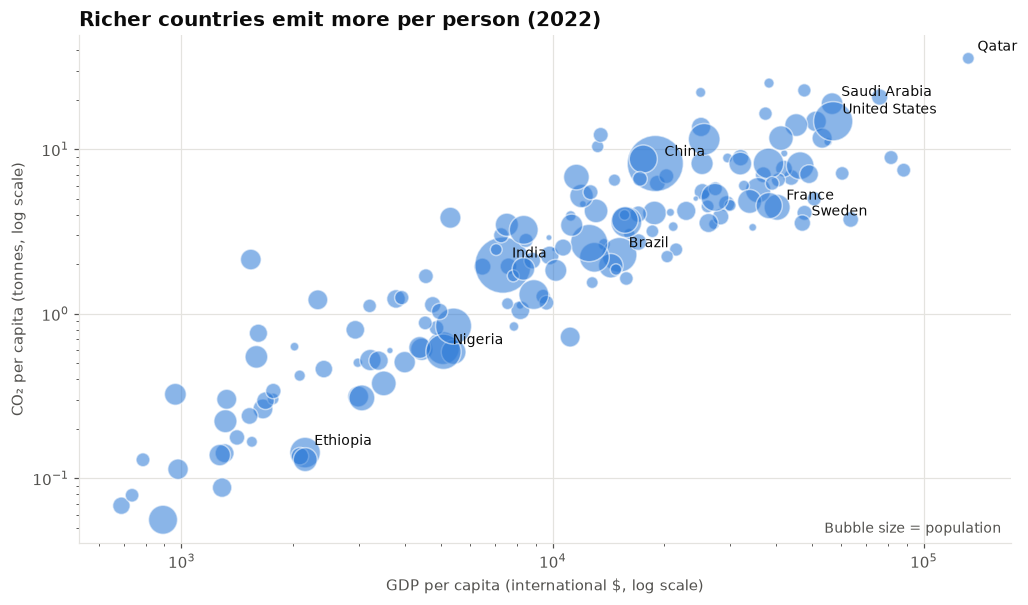

n = 164 countries   Pearson r on logs = 0.91   Spearman rho = 0.90


In [7]:
g = countries[countries.year == GDP_YEAR].dropna(subset=["gdp_per_capita", "co2_per_capita", "population"])

fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.scatter(g.gdp_per_capita, g.co2_per_capita, s=np.sqrt(g.population) / 28, color=BLUE, alpha=0.55, edgecolor="white", linewidth=1)
ax.set(xscale="log", yscale="log", title=f"Richer countries emit more per person ({GDP_YEAR})",
       xlabel="GDP per capita (international $, log scale)", ylabel="CO₂ per capita (tonnes, log scale)")
for name in ["China", "United States", "India", "Qatar", "Nigeria", "France", "Sweden", "Saudi Arabia", "Brazil", "Ethiopia"]:
    r = g[g.country == name]
    if len(r):
        ax.annotate(name, (r.gdp_per_capita.iloc[0], r.co2_per_capita.iloc[0]), xytext=(6, 5), textcoords="offset points", fontsize=9)
ax.text(0.99, 0.02, "Bubble size = population", transform=ax.transAxes, ha="right", color=MUTED, fontsize=9)
save("06_gdp_vs_co2")

r_log = np.corrcoef(np.log10(g.gdp_per_capita), np.log10(g.co2_per_capita))[0, 1]
rho = g[["gdp_per_capita", "co2_per_capita"]].corr(method="spearman").iloc[0, 1]
print(f"n = {len(g)} countries   Pearson r on logs = {r_log:.2f}   Spearman rho = {rho:.2f}")

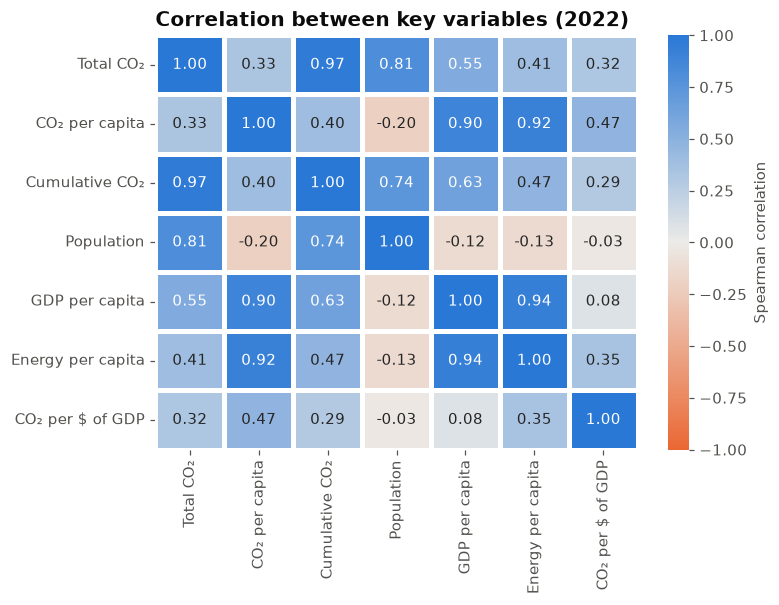

In [8]:
labels = {"co2": "Total CO₂", "co2_per_capita": "CO₂ per capita", "cumulative_co2": "Cumulative CO₂",
          "population": "Population", "gdp_per_capita": "GDP per capita", "energy_per_capita": "Energy per capita",
          "co2_per_gdp": "CO₂ per $ of GDP"}
corr = countries[countries.year == GDP_YEAR][list(labels)].rename(columns=labels).corr(method="spearman")

diverging = LinearSegmentedColormap.from_list("div", [ORANGE, "#ecebe7", BLUE])
fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=diverging, vmin=-1, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title(f"Correlation between key variables ({GDP_YEAR})"); ax.grid(False)
save("07_correlation")

**What we learn**

- GDP per capita and CO₂ per capita are **very strongly related** (Spearman 0.90, Pearson 0.91 on logs, 164 countries). On log scales the relationship is close to a straight line.
- Energy use per capita is the link between the two: it correlates 0.94 with GDP per capita and 0.91 with CO₂ per capita.
- Total CO₂ follows **population** (0.81), but population says almost nothing about emissions per person (−0.20). Size and intensity are two different questions.
- CO₂ per dollar of GDP is unrelated to wealth (0.08): rich countries are not systematically cleaner or dirtier per dollar produced.
- Countries at the same income level still differ a lot (France and Sweden sit well below the United States), so wealth is not the whole story. Correlation here does not prove causation.

## 7. Decoupling: can an economy grow while emissions fall?

For each country we compare the change in GDP per capita with the change in CO₂ per capita between 2000 and 2022 (countries above 5 million people).

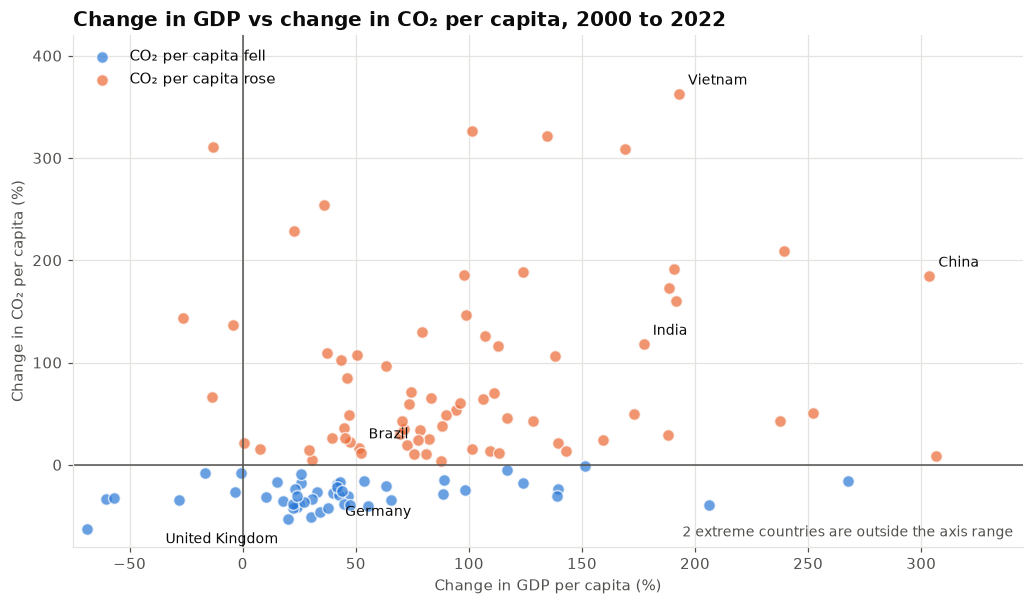

Outside the axis range: {'Cambodia': {'gdp': 131.0, 'co2': 666.0}, 'Laos': {'gdp': 223.0, 'co2': 1590.0}}
121 countries: 41 grew GDP and cut CO₂ (decoupled), 69 grew both, 11 saw GDP per capita fall


,gdp,co2
country,,
United Kingdom,20.0,-53.0
France,18.0,-35.0
United States,24.0,-31.0
Germany,40.0,-27.0
India,177.0,118.0
China,304.0,185.0
Vietnam,193.0,363.0


In [9]:
a0 = countries[countries.year == 2000].set_index("country")
a1 = countries[countries.year == GDP_YEAR].set_index("country")
ch = pd.DataFrame({"gdp": (a1.gdp_per_capita / a0.gdp_per_capita - 1) * 100,
                   "co2": (a1.co2_per_capita / a0.co2_per_capita - 1) * 100,
                   "population": a1.population}).dropna()
ch = ch[ch.population > 5e6]
ch["group"] = np.where(ch.co2 < 0, "CO₂ per capita fell", "CO₂ per capita rose")

fig, ax = plt.subplots(figsize=(9.5, 5.6))
for grp, c in [("CO₂ per capita fell", BLUE), ("CO₂ per capita rose", ORANGE)]:
    d = ch[ch.group == grp]
    ax.scatter(d.gdp, d.co2, s=60, color=c, alpha=0.7, edgecolor="white", linewidth=1, label=grp)
ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)
offsets = {"United Kingdom": (-6, -16, "right"), "Germany": (8, -15, "left"), "China": (6, 6, "left"),
           "India": (6, 6, "left"), "Vietnam": (6, 6, "left"), "Brazil": (6, 6, "left")}
for name, (dx, dy, ha) in offsets.items():
    ax.annotate(name, (ch.loc[name, "gdp"], ch.loc[name, "co2"]), xytext=(dx, dy), textcoords="offset points", fontsize=9, ha=ha)
XLIM, YLIM = (-75, 345), (-80, 420)
hidden = ((ch.co2 > YLIM[1]) | (ch.gdp > XLIM[1]) | (ch.gdp < XLIM[0])).sum()
ax.set(xlim=XLIM, ylim=YLIM)
ax.text(0.99, 0.02, f"{hidden} extreme countries are outside the axis range", transform=ax.transAxes, ha="right", color=MUTED, fontsize=9)
ax.set(title=f"Change in GDP vs change in CO₂ per capita, 2000 to {GDP_YEAR}",
       xlabel="Change in GDP per capita (%)", ylabel="Change in CO₂ per capita (%)")
ax.legend(loc="upper left")
save("08_decoupling")
print("Outside the axis range:", ch[(ch.co2 > YLIM[1]) | (ch.gdp > XLIM[1]) | (ch.gdp < XLIM[0])].round(0)[["gdp", "co2"]].to_dict("index"))

grew = ch.gdp > 0
print(f"{len(ch)} countries: {(grew & (ch.co2 < 0)).sum()} grew GDP and cut CO₂ (decoupled), "
      f"{(grew & (ch.co2 >= 0)).sum()} grew both, {(~grew).sum()} saw GDP per capita fall")
ch.loc[["United Kingdom", "France", "United States", "Germany", "India", "China", "Vietnam"], ["gdp", "co2"]].round(0)

**What we learn**

- Of 121 countries, **41 grew their GDP per capita while cutting CO₂ per capita** (bottom-right quadrant). 69 grew both, and 11 saw GDP per capita fall.
- Decoupling is concentrated in rich economies: United Kingdom (GDP +20%, CO₂ −53%), United States (+24%, −31%), Germany (+40%, −27%).
- Fast-growing economies raised both: China (GDP +304%, CO₂ +185%), India (+177%, +118%), Vietnam (+193%, +363%).
- Note that in China and India emissions grew more slowly than GDP, which is a relative decoupling. Section 8 adds a caveat: part of the rich countries' decline was moved abroad through trade.

## 8. Emissions embedded in trade

Standard figures count emissions where goods are **produced**. Consumption-based figures assign them to where goods are **consumed**. The difference is the CO₂ embedded in trade.

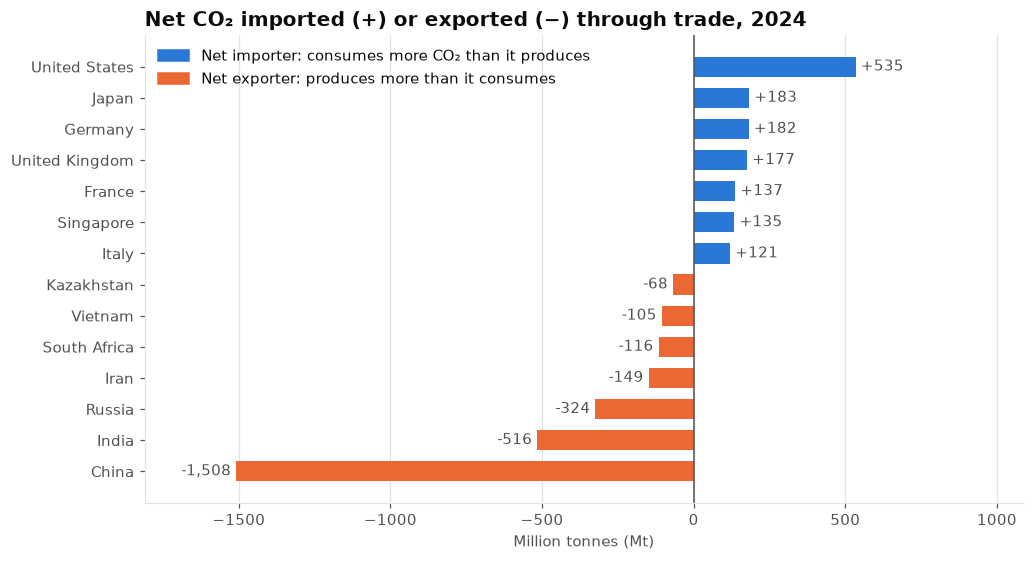

120 countries with trade data


,co2,consumption_co2,trade_co2,trade_co2_share
country,,,,
United States,4912.0,5447.0,535.0,11.0
Japan,970.0,1153.0,183.0,19.0
Germany,574.0,756.0,182.0,32.0
United Kingdom,318.0,494.0,177.0,56.0
France,261.0,399.0,137.0,53.0
Singapore,54.0,188.0,135.0,251.0
Italy,298.0,419.0,121.0,40.0
Kazakhstan,291.0,223.0,-68.0,-23.0
Vietnam,357.0,252.0,-105.0,-29.0


In [10]:
t = latest.dropna(subset=["trade_co2"])
sel = pd.concat([t.nlargest(7, "trade_co2"), t.nsmallest(7, "trade_co2")]).sort_values("trade_co2")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = np.where(sel.trade_co2 > 0, BLUE, ORANGE)
ax.barh(sel.country, sel.trade_co2, color=colors, height=0.65)
for y, v in enumerate(sel.trade_co2):
    ax.text(v, y, f" {v:+,.0f} " , va="center", ha="left" if v > 0 else "right", color=MUTED)
ax.axvline(0, color=MUTED, lw=1)
lim = sel.trade_co2.abs().max() * 1.2
ax.set(title=f"Net CO₂ imported (+) or exported (−) through trade, {YEAR}", xlabel="Million tonnes (Mt)", xlim=(-lim, lim * 0.6))
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["Net importer: consumes more CO₂ than it produces", "Net exporter: produces more than it consumes"], loc="upper left")
save("09_trade")

print(f"{len(t)} countries with trade data")
sel.set_index("country")[["co2", "consumption_co2", "trade_co2", "trade_co2_share"]].round(0).iloc[::-1]

**What we learn**

- **China is the largest net exporter of CO₂** (about 1.5 Gt, 12% of its production emissions): a large part of what it emits goes into goods consumed elsewhere. India and Russia follow.
- **The United States is the largest net importer** (+535 Mt, 11% on top of its production emissions).
- For some European countries the gap is large in relative terms: consumption emissions are 56% higher than production emissions in the United Kingdom and 53% higher in France.
- This data covers 120 countries, so smaller economies are missing from the ranking.

## 9. Country profile (drill-down)

A reusable function: change the country name to profile any country against the world.

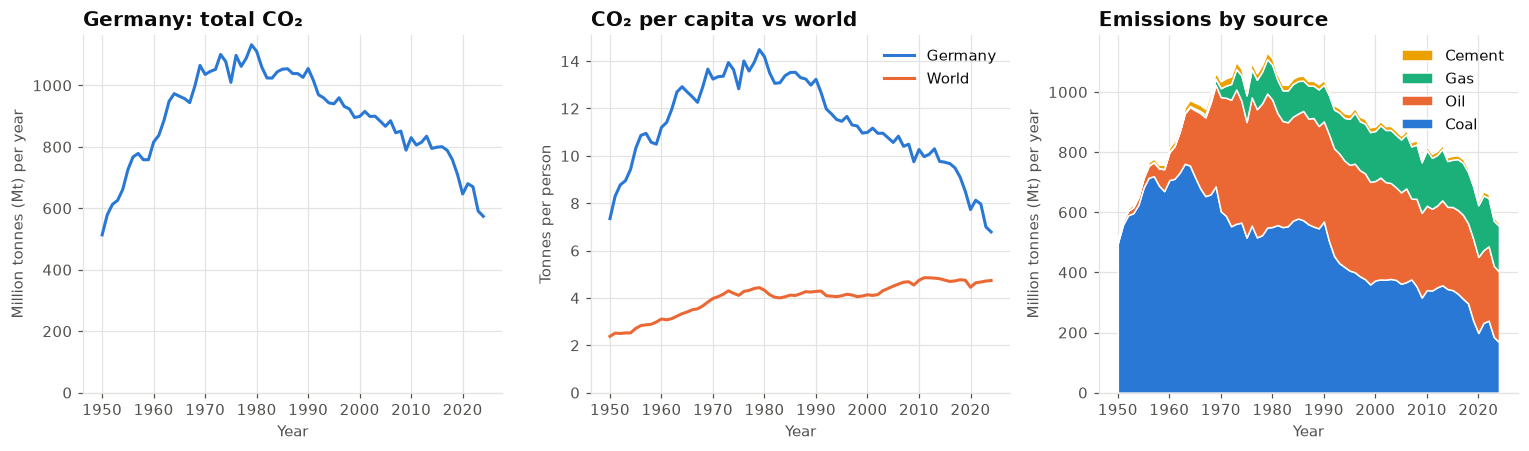

Germany: peak 1,132 Mt in 1979; 2024: 574 Mt (-49% vs peak); 6.8 t per person vs world 4.7


In [11]:
def country_profile(name, start=1950):
    c = countries[(countries.country == name) & countries.year.between(start, YEAR)].set_index("year")
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

    axes[0].plot(c.index, c.co2, color=BLUE)
    axes[0].set(title=f"{name}: total CO₂", xlabel="Year", ylabel="Million tonnes (Mt) per year", ylim=(0, None))

    axes[1].plot(c.index, c.co2_per_capita, color=BLUE, label=name)
    axes[1].plot(world.loc[start:YEAR].index, world.loc[start:YEAR, "co2_per_capita"], color=ORANGE, label="World")
    axes[1].set(title="CO₂ per capita vs world", xlabel="Year", ylabel="Tonnes per person", ylim=(0, None))
    axes[1].legend()

    mix = c[["coal_co2", "oil_co2", "gas_co2", "cement_co2"]].fillna(0)
    axes[2].stackplot(mix.index, mix.T.values, labels=["Coal", "Oil", "Gas", "Cement"], colors=SERIES[:4], edgecolor="white", linewidth=1)
    axes[2].set(title="Emissions by source", xlabel="Year", ylabel="Million tonnes (Mt) per year")
    axes[2].legend(loc="upper right", reverse=True)
    save(f"10_profile_{name.lower().replace(' ', '_')}")

    peak = c.co2.idxmax()
    print(f"{name}: peak {c.co2.max():,.0f} Mt in {peak}; {YEAR}: {c.co2.loc[YEAR]:,.0f} Mt ({c.co2.loc[YEAR] / c.co2.max() - 1:+.0%} vs peak); "
          f"{c.co2_per_capita.loc[YEAR]:.1f} t per person vs world {world.loc[YEAR, 'co2_per_capita']:.1f}")

country_profile("Germany")

**What we learn (Germany)**

- Emissions peaked in 1979 at 1,132 Mt and have since fallen by 49% to 574 Mt.
- Per person, Germany is now at 6.8 t, still above the world average of 4.7 t, but the gap has narrowed sharply.
- The fall comes mostly from coal, which dropped from about 550 Mt in 1979 to 168 Mt in 2024. Oil is now the largest source.

## 10. Summary of findings

| # | Finding | Evidence |
|---|---|---|
| 1 | Emissions are 6.5 times their 1950 level and still rising; coal remains the largest source (41%) | Section 3 |
| 2 | Emissions are concentrated: 3 countries produce 53%, 10 countries produce 69% | Section 4 |
| 3 | The ranking depends on the measure: China leads in total, Gulf states per person, the United States cumulatively | Section 4 |
| 4 | Per-capita emissions are highly unequal and right-skewed; two thirds of countries are below the world average | Section 2 |
| 5 | The centre of emissions moved to Asia (61% of the total) while Europe fell 40% since 1990 | Section 5 |
| 6 | Wealth and emissions per person are strongly linked (ρ = 0.90), through energy use | Section 6 |
| 7 | Growth without rising emissions is possible: 41 of 121 countries did it between 2000 and 2022 | Section 7 |
| 8 | Part of rich countries' emissions is imported: China net-exports about 1.5 Gt of CO₂ in goods | Section 8 |

**Limitations**

- Historical values (before about 1950) are estimates and cover few countries.
- GDP ends in 2022 and trade-adjusted emissions cover 120 countries, so sections 6 to 8 use fewer countries than the rest.
- The analysis covers CO₂ from fossil fuels and industry, not land-use change or other greenhouse gases.
- All relationships shown are associations, not proof of cause and effect.

Every chart is saved as a PNG in the `figures/` folder, ready for the slides.